# Hotel Bookings: Basic Data Cleaning (Report-1 + Report-2)

Every step below does **one small job**. Run the cells from top to bottom (Run All).

**Got `ModuleNotFoundError: No module named 'pandas'`?** The notebook is using a Python that does not have pandas.
Click **Select Kernel** (top-right) and choose the Python where pandas is installed, or run `%pip install pandas numpy matplotlib` once and restart the kernel.

**Steps:** load -> remove private columns (phone, email) -> trim spaces -> hidden blanks -> fix labels -> fix names -> make numbers -> remove impossible values
-> make dates -> fix date mistakes -> room number -> remove duplicates -> fill gaps -> check -> charts -> save

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Change these two paths if your files are somewhere else
REPORT_1_PATH = "Report_1_clean.csv"
REPORT_2_PATH = "Report_2_clean.csv"

# None = read every row. For a quick test run, write 100000 instead of None
ROWS_TO_READ = None

## Step 0: Load the two reports
- `dtype=str` reads every column as plain text, so pandas does not guess the types wrongly.
- `keep_default_na=False` stops pandas from turning the word `None` (a real answer in `special_request`) into a missing value.

In [2]:
import pandas as pd
from pathlib import Path

def find_csv(filename):
    for folder in (Path.cwd(), Path.cwd().parent):
        matches = list(folder.rglob(filename))
        if matches:
            return str(matches[0])

    raise FileNotFoundError(
        f"Could not find {filename}. Place it in the notebook folder "
        "or update its path in the setup cell."
    )

REPORT_1_PATH = find_csv("Report_1_clean.csv")
REPORT_2_PATH = find_csv("Report_2_clean.csv")

report_1 = pd.read_csv(REPORT_1_PATH, dtype=str, keep_default_na=False, nrows=ROWS_TO_READ)
report_2 = pd.read_csv(REPORT_2_PATH, dtype=str, keep_default_na=False, nrows=ROWS_TO_READ)

print(report_1.shape)
print(report_2.shape)

(1200000, 26)
(500000, 26)


In [3]:
report_1.head()

,booking_id,guest_id,guest_name,gender,age,nationality,city,phone,email,hotel_name,...,num_guests,booking_channel,room_rate_per_night,discount_pct,total_amount,payment_method,payment_status,is_cancelled,special_request,review_rating
0,BK00372606,G0650418,Sadia Uddin,Male,35,U.S.A,Rajshahi,+8803153598787,sadia.uddin350@gmail.com,Sea Pearl Cox's Bazar,...,1,Walk-in,4698.57,0.15,"BDT 23,962.71",,Paid,No,None,4.3
1,BK00551205,G0340921,Sabbir Smith,N/A,31,Bangladesh,Dhaka,+8809331324757,sabbir.smith30@yahoo.com,Port City Chattogram,...,2,Agoda,"BDT 6,518.60",0.05,6192.67,Credit Card,Paid,No,None,
2,BK00240321,G0443941,Sadia Begum,Male,40,Pakistan,Karachi,+924416144887,sadia.begum701@gmail.com,Sea Pearl Cox's Bazar,...,6,Expedia,4031.8,0.05,22981.26,bKash,Paid,No,Sea view,
3,BK01047362,G0621753,Raj Hossain,Female,29,Bangladesh,,008804451464150,raj.hossain118@gmail.con,port city chattogram,...,5,Booking.com,6853.72,0.15,5825.66,Credit Card,Paid,No,Extra bed,4.1
4,BK00555363,G0517578,Karim Li,Female,30,Bangladesh,Rajshahi,+880-374 147-747 8,karim.li209@gmail.com,Port City Chattogram,...,2,Direct,4527.39,0.0,$13582.17,Nagad,Refunded,No,None,5.0


In [4]:
report_2.head()

,booking_id,guest_id,guest_name,gender,age,nationality,city,phone,email,hotel_name,...,num_guests,booking_channel,room_rate_per_night,discount_pct,total_amount,payment_method,payment_status,is_cancelled,special_request,review_rating
0,BK01248848,G0592483,Jannat Islam,Male,28,Japan,Tokyo,00815290554568,jannat.islam142@yahoo.com,Riverside Khulna,...,1,Booking.com,"BDT 4,130.79",,8261.58,Nagad,Paid,No,,
1,BK01612573,G0601639,Raj Rahman,Male,42,bangladesh,Dhaka,+8803887104864,raj.rahman468@gmail.com,Sea Pearl Cox's Bazar,...,1,Direct,36943.94,0.0,147775.76,Online,Pending,No,None,3.5
2,BK01592783,G0070887,Yuki Ahmed,Female,22,Malaysia,Kuala Lumpur,+609-072 128-261,,Sea Pearl Cox's Bazar,...,4,Expedia,"BDT 8,654.19",0.1,7788.77,Credit Card,Paid,No,Breakfast included,3.2
3,BK01305681,G0589282,Sabbir Ahmed,Female,27,Bangladesh,Dhaka,+8807969373634,sabbir.ahmed80@gmail.com,Riverside Khulna,...,6,Booking.com,4546.87,0.2,3637.5,Credit Card,Paid,No,None,4.0
4,BK01302282,G0316692,Noah Hasan,Male,18,Bangladesh,Rajshahi,+8805635740792,noah.hasan165@gmail.com,Sea Pearl Cox's Bazar,...,2,Booking.com,"BDT 8,220.68",0.2,19729.63,Nagad,Paid,No,Late checkout,3.8


In [5]:
# Both reports must have the same columns before we join them
print(report_1.columns.equals(report_2.columns))

# Remember which report each row came from, then join them
report_1["source_report"] = "Report-1"
report_2["source_report"] = "Report-2"

report = pd.concat([report_1, report_2], ignore_index=True)
print(report.shape)

# Privacy: remove the phone and email columns straight away, so this private
# contact information never appears in any later step, chart or the saved files
private_columns = ["phone", "email"]
report = report.drop(columns=private_columns, errors="ignore")
print("Private columns removed:", [c for c in private_columns if c not in report.columns])
print(report.shape)

True
(1700000, 27)
Private columns removed: ['phone', 'email']
(1700000, 25)


## Step 1: Remove extra spaces
`"  Dhaka "` and `"Dhaka"` are the same city, but the computer sees them as different. `strip()` removes spaces at the start and end.

In [6]:
for column in report.columns:
    report[column] = report[column].str.strip()

## Step 2: Find hidden blanks
Cells like `NULL`, `N/A`, `-`, `?` or `missing` look like normal text, so `isnull()` cannot see them.
We replace them with a real missing value (`NaN`) first, then count.

In [7]:
hidden_blanks = ["", "NULL", "null", "N/A", "n/a", "NA", "na", "-", "?", "missing", "unknown"]
report = report.replace(hidden_blanks, np.nan)

missing_before = report.isnull().sum()
print("Missing values in each column:")
print(missing_before)

Missing values in each column:
booking_id                  0
guest_id                    0
guest_name              17083
gender                  68255
age                    101817
nationality             51202
city                   119349
hotel_name               8618
room_type                   0
room_number             34075
booking_date                0
check_in_date               0
check_out_date          13416
nights                   8501
num_guests                  0
booking_channel         33700
room_rate_per_night         0
discount_pct            85016
total_amount            25471
payment_method          50843
payment_status              0
is_cancelled                0
special_request         67808
review_rating          576391
source_report               0
dtype: int64


## Step 3: Make labels consistent
`deluxe`, `DELUXE` and `Deluxe` should be one label. `title()` fixes the capital letters,
then `replace()` fixes the short names (like `Dlx`). After each group we print the labels, so you can see they are clean.

In [8]:
# Room type
report["room_type"] = report["room_type"].str.title()
report["room_type"] = report["room_type"].replace({"Dlx": "Deluxe", "Std": "Standard", "Ste": "Suite", "Exec": "Executive"})
print(report["room_type"].value_counts())

room_type
Standard        594766
Deluxe          476461
Family          204161
Suite           203345
Executive       170144
Presidential     51123
Name: count, dtype: int64


In [9]:
# Booking channel, payment method and payment status
report["booking_channel"] = report["booking_channel"].str.title()
report["booking_channel"] = report["booking_channel"].replace({"Booking.Com": "Booking.com", "Walk-In": "Walk-in"})

report["payment_method"] = report["payment_method"].str.title()
report["payment_method"] = report["payment_method"].replace(
    {"Bkash": "bKash", "B-Kash": "bKash", "Cc": "Credit Card", "Credit-Card": "Credit Card"})

report["payment_status"] = report["payment_status"].str.title()

print(report["booking_channel"].value_counts())
print(report["payment_method"].value_counts())
print(report["payment_status"].value_counts())

booking_channel
Booking.com     366972
Direct          299397
Agoda           249956
Walk-in         166601
Corporate       166475
Travel Agent    150231
Phone           133496
Expedia         133172
Name: count, dtype: int64
payment_method
Credit Card      415886
Cash             295822
bKash            264824
Debit Card       192294
Online           192217
Bank Transfer    159812
Nagad            128302
Name: count, dtype: int64
payment_status
Paid        1223249
Pending      169996
Partial      135774
Refunded     102095
Failed        68886
Name: count, dtype: int64


In [10]:
# Guest details: gender, nationality, city, hotel, cancelled
report["gender"] = report["gender"].str.title()
report["is_cancelled"] = report["is_cancelled"].str.title()

report["nationality"] = report["nationality"].str.title()
report["nationality"] = report["nationality"].replace(
    {"Bd": "Bangladesh", "Bangladeshi": "Bangladesh", "U.S.A": "USA", "Usa": "USA",
     "United Kingdom": "UK", "Uk": "UK", "Uae": "UAE", "Ind": "India"})

report["city"] = report["city"].str.title()
report["city"] = report["city"].replace({"Cox'S Bazar": "Cox's Bazar"})

report["hotel_name"] = report["hotel_name"].str.title()
report["hotel_name"] = report["hotel_name"].replace({"Sea Pearl Cox'S Bazar": "Sea Pearl Cox's Bazar"})

print(report["gender"].value_counts())
print(report["nationality"].value_counts())
print(report["city"].value_counts())
print(report["hotel_name"].value_counts())

gender
Male      898496
Female    700830
Other      32419
Name: count, dtype: int64
nationality
Bangladesh      748413
India           199714
USA             102968
UK              102267
UAE              79977
China            79903
Malaysia         64081
Japan            63894
Singapore        48243
Pakistan         47971
Australia        32040
Germany          31919
Canada           31591
Saudi Arabia     15817
Name: count, dtype: int64
city
Sylhet          118989
Rajshahi        118858
Cox's Bazar     118827
Dhaka           118790
Khulna          118551
Chattogram      117862
Kuala Lumpur     63399
Kolkata          47705
Singapore        47684
Mumbai           47440
Delhi            47344
Bengaluru        47192
Manchester       47101
London           47010
Abu Dhabi        39899
Shanghai         39596
Beijing          39389
Dubai            39254
Dallas           31681
Sydney           31668
Tokyo            31648
Chicago          31634
New York         31621
Osaka            31525

## Step 4: Fix guest names
Some names have a doubled letter typo (`Raahim`). In this data none of the real names contain `aa`, so replacing `aa` with `a` repairs them.
(If your real names contain `aa`, delete that line.)
Order: `lower()` first (so `AA` and `aa` are treated the same), then repair, then `title()` makes `rahim khan` look like `Rahim Khan`.

In [11]:
report["guest_name"] = report["guest_name"].str.lower()
report["guest_name"] = report["guest_name"].str.replace("aa", "a", regex=False)
report["guest_name"] = report["guest_name"].str.title()

# There should be only a small number of different first names now
print(report["guest_name"].str.split().str[0].nunique(), "different first names")

32 different first names


## Step 5: Turn text into numbers
Values like `BDT 4,741.41` or `$300` are text. We remove everything except digits, the dot and the minus sign, then convert with `to_numeric`.
`errors="coerce"` means "if it still cannot be a number, make it missing" instead of crashing.

In [12]:
# Money columns
for column in ["room_rate_per_night", "total_amount"]:
    report[column] = report[column].str.replace(r"[^0-9.\-]", "", regex=True)
    report[column] = pd.to_numeric(report[column], errors="coerce")

In [13]:
# Discount: some rows say "10%", others say 0.1. We want a percent (10) everywhere.
report["discount_pct"] = report["discount_pct"].str.replace("%", "", regex=False)
report["discount_pct"] = pd.to_numeric(report["discount_pct"], errors="coerce")

# A value of 1 or less is a fraction (0.15 means 15%), so multiply by 100
is_fraction = report["discount_pct"] <= 1
report.loc[is_fraction, "discount_pct"] = report.loc[is_fraction, "discount_pct"] * 100

In [14]:
# Nights: words like "two" and texts like "3 nights"
report["nights"] = report["nights"].replace({"one": "1", "two": "2", "three": "3", "four": "4", "five": "5"})
report["nights"] = report["nights"].str.replace(r"[^0-9]", "", regex=True)

# Plain numeric columns
for column in ["nights", "age", "num_guests", "review_rating"]:
    report[column] = pd.to_numeric(report[column], errors="coerce")

report[["age", "nights", "num_guests", "room_rate_per_night", "discount_pct", "total_amount", "review_rating"]].describe()

,age,nights,num_guests,room_rate_per_night,discount_pct,total_amount,review_rating
count,1.598183e+06,1.691499e+06,1.700000e+06,1.700000e+06,1.614984e+06,1.674529e+06,1.123609e+06
mean,3.810372e+01,3.183769e+00,3.076845e+00,2.134732e+05,7.140705e+00,4.497233e+04,3.949550e+00
std,4.499898e+01,1.484290e+00,5.137984e+00,4.488582e+06,7.489870e+00,4.408445e+05,9.735744e-01
min,-1.000000e+00,1.000000e+00,-2.000000e+00,-5.000000e+03,0.000000e+00,-1.200000e+03,-1.000000e+00
25%,2.700000e+01,2.000000e+00,2.000000e+00,5.191240e+03,0.000000e+00,1.283778e+04,3.400000e+00
50%,3.500000e+01,3.000000e+00,3.000000e+00,7.425335e+03,5.000000e+00,2.037992e+04,4.000000e+00
75%,4.400000e+01,4.000000e+00,4.000000e+00,1.019101e+04,1.500000e+01,3.174448e+04,4.600000e+00
max,9.990000e+02,1.300000e+01,9.900000e+01,1.000000e+08,2.000000e+01,9.999999e+06,1.000000e+01


## Step 6: Remove impossible values
Look at the `min` and `max` rows above: ages like -1 or 999, a rating of 10, or a rate of 99,999,999 cannot be real.
`between(low, high)` is True for allowed values. `where()` keeps those and turns everything else into missing.
Change the limits if your course data allows other ranges.

In [15]:
report["age"] = report["age"].where(report["age"].between(18, 100))
report["nights"] = report["nights"].where(report["nights"].between(1, 30))
report["num_guests"] = report["num_guests"].where(report["num_guests"].between(1, 10))
report["room_rate_per_night"] = report["room_rate_per_night"].where(report["room_rate_per_night"].between(1000, 60000))
report["total_amount"] = report["total_amount"].where(report["total_amount"].between(1, 2000000))
report["discount_pct"] = report["discount_pct"].where(report["discount_pct"].between(0, 50))
report["review_rating"] = report["review_rating"].where(report["review_rating"].between(1, 5))

# A cancelled booking cannot have a review rating
report.loc[report["is_cancelled"] == "Yes", "review_rating"] = np.nan

## Step 7: Turn text into dates
This data uses six date styles. We try one format at a time, and every date that matches fills in the answer.

| Example | Format |
|---|---|
| 2024-12-29 | `%Y-%m-%d` |
| 2024/12/29 | `%Y/%m/%d` |
| 19/05/2025 (day first) | `%d/%m/%Y` |
| 09-11-2023 (month first) | `%m-%d-%Y` |
| 14-Oct-2023 | `%d-%b-%Y` |
| October 14, 2023 | `%B %d, %Y` |

We do **not** use one `dayfirst=True` rule, because it would read the month-first dates (`09-11-2023` = 11 September) as 9 November.

In [16]:
date_formats = ["%Y-%m-%d", "%Y/%m/%d", "%d/%m/%Y", "%m-%d-%Y", "%d-%b-%Y", "%B %d, %Y"]

for column in ["booking_date", "check_in_date", "check_out_date"]:
    result = pd.to_datetime(report[column], format=date_formats[0], errors="coerce")
    for date_format in date_formats[1:]:
        result = result.fillna(pd.to_datetime(report[column], format=date_format, errors="coerce"))
    report[column] = result

print(report[["booking_date", "check_in_date", "check_out_date"]].isnull().sum())

# Sanity test: a guest cannot check in before booking. This should be about 100%
share = (report["check_in_date"] >= report["booking_date"]).mean()
print("Check-in is on or after booking date:", round(share * 100, 2), "%")

booking_date          0
check_in_date         0
check_out_date    13416
dtype: int64
Check-in is on or after booking date: 100.0 %


## Step 8: Fix date mistakes
1. Some rows have check-out **before** check-in. The two dates were swapped, so we swap them back.
2. `nights` should be the number of days between the two dates, so we calculate it.
3. If check-out is missing, it is check-in + nights.

In [17]:
# 1. Swap back reversed dates
wrong_order = report["check_out_date"] < report["check_in_date"]
print("Rows with reversed dates:", wrong_order.sum())

saved_check_in = report.loc[wrong_order, "check_in_date"].copy()
report.loc[wrong_order, "check_in_date"] = report.loc[wrong_order, "check_out_date"]
report.loc[wrong_order, "check_out_date"] = saved_check_in

# 2. Nights from the dates (keep the old value when a date is missing)
nights_from_dates = (report["check_out_date"] - report["check_in_date"]).dt.days
report["nights"] = nights_from_dates.fillna(report["nights"])

# 3. Missing check-out = check-in + nights
no_check_out = report["check_out_date"].isnull() & report["nights"].notnull()
report.loc[no_check_out, "check_out_date"] = report.loc[no_check_out, "check_in_date"] + pd.to_timedelta(report.loc[no_check_out, "nights"], unit="D")

Rows with reversed dates: 6762


## Step 9: Room number
Phone and email were removed in Step 0, so only the room number needs checking here.
- **Room number:** must be three digits from 101 to 899.

In [18]:
# Room number
room_ok = report["room_number"].str.match(r"^[1-8][0-9][0-9]$", na=False)
report["room_number"] = report["room_number"].where(room_ok)

print("Room numbers missing:", report["room_number"].isnull().sum())

Room numbers missing: 40696


## Step 10: Remove duplicates
We do this **after** cleaning, so rows that only differed by spaces or capital letters are now identical and get caught.
1. Rows that are exactly the same.
2. The same `booking_id` more than once.
3. The same guest with the same check-in and check-out under a different `booking_id` (a double entry).

In [19]:
rows_start = len(report)

report = report.drop_duplicates()
print("After removing exact duplicates:", len(report))

report = report.drop_duplicates(subset="booking_id")
print("After removing repeated booking_id:", len(report))

report = report.drop_duplicates(subset=["guest_id", "check_in_date", "check_out_date"])
print("After removing double entries:", len(report))

print("Total rows removed:", rows_start - len(report))

After removing exact duplicates: 1675629
After removing repeated booking_id: 1675376
After removing double entries: 1658644
Total rows removed: 41356


## Step 11: Fill the remaining gaps
Simple rules you can explain in your VIVA:
- text columns -> `Unknown` (`special_request` -> `None`)
- `age` and `num_guests` -> the median (middle value)
- `discount_pct` -> 0
- a missing rate or total is worked out from the formula `total = rate x nights x (1 - discount/100)`
- if the rate is still missing, use the median rate of the same room type

Room number and review rating stay missing, because inventing them would create false data.

In [20]:
# Text columns
for column in ["gender", "nationality", "city", "hotel_name", "booking_channel", "payment_method", "payment_status"]:
    report[column] = report[column].fillna("Unknown")
report["special_request"] = report["special_request"].fillna("None")

# Numbers
report["age"] = report["age"].fillna(report["age"].median()).round()
report["num_guests"] = report["num_guests"].fillna(report["num_guests"].median()).round()
report["discount_pct"] = report["discount_pct"].fillna(0)

# Rate and total
discount_factor = 1 - report["discount_pct"] / 100
report["room_rate_per_night"] = report["room_rate_per_night"].fillna(report["total_amount"] / (report["nights"] * discount_factor))

same_room_median = report.groupby("room_type")["room_rate_per_night"].transform("median")
report["room_rate_per_night"] = report["room_rate_per_night"].fillna(same_room_median)

report["total_amount"] = report["total_amount"].fillna(report["room_rate_per_night"] * report["nights"] * discount_factor)

report["room_rate_per_night"] = report["room_rate_per_night"].round(2)
report["total_amount"] = report["total_amount"].round(2)

# Whole numbers should look like whole numbers
report["age"] = report["age"].astype(int)
report["num_guests"] = report["num_guests"].astype(int)
report["nights"] = report["nights"].astype("Int64")

## Step 12: Check the result
Everything below should look sensible: no repeated booking IDs, no check-out before check-in, and sensible min/max values.

In [21]:
print("Rows:", len(report))
print("Repeated booking_id:", report["booking_id"].duplicated().sum())
print("Check-out before check-in:", (report["check_out_date"] < report["check_in_date"]).sum())
print()
print("Missing values left:")
print(report.isnull().sum()[report.isnull().sum() > 0])

Rows: 1658644
Repeated booking_id: 0
Check-out before check-in: 0

Missing values left:
guest_name         16682
room_number        39682
check_out_date        64
nights                64
total_amount           1
review_rating     581054
dtype: int64


In [22]:
report[["age", "nights", "num_guests", "room_rate_per_night", "discount_pct", "total_amount", "review_rating"]].describe()

,age,nights,num_guests,room_rate_per_night,discount_pct,total_amount,review_rating
count,1.658644e+06,1658580.0,1.658644e+06,1.658644e+06,1.658644e+06,1.658643e+06,1.077590e+06
mean,3.581432e+01,3.201885,2.800530e+00,8.610599e+03,6.784183e+00,2.560622e+04,3.939449e+00
std,1.084194e+01,1.484819,1.332300e+00,5.202805e+03,7.464503e+00,2.094707e+04,7.988084e-01
min,1.800000e+01,1.0,1.000000e+00,2.657230e+03,0.000000e+00,2.616120e+03,1.000000e+00
25%,2.800000e+01,2.0,2.000000e+00,5.210520e+03,0.000000e+00,1.291304e+04,3.400000e+00
50%,3.500000e+01,3.0,3.000000e+00,7.424895e+03,5.000000e+00,2.041824e+04,4.000000e+00
75%,4.300000e+01,4.0,4.000000e+00,1.016034e+04,1.500000e+01,3.171939e+04,4.600000e+00
max,8.500000e+01,13.0,8.000000e+00,4.971967e+04,2.000000e+01,4.868709e+05,5.000000e+00


## Step 13: Charts

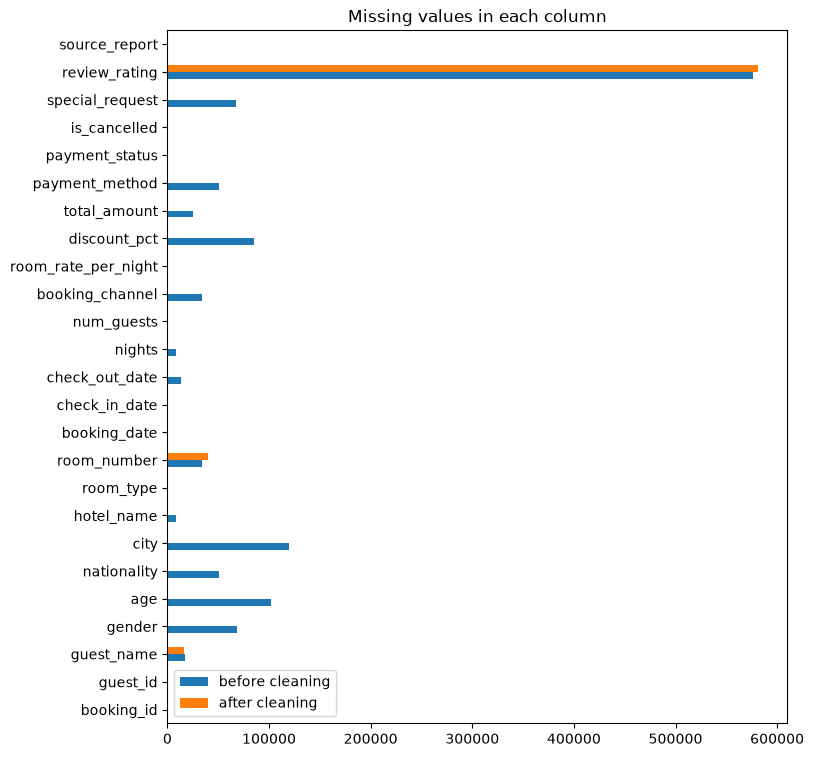

In [23]:
# Missing values before and after cleaning
missing_after = report.isnull().sum()
compare = pd.DataFrame({"before cleaning": missing_before, "after cleaning": missing_after})
compare.plot.barh(figsize=(8, 9), title="Missing values in each column")
plt.show()

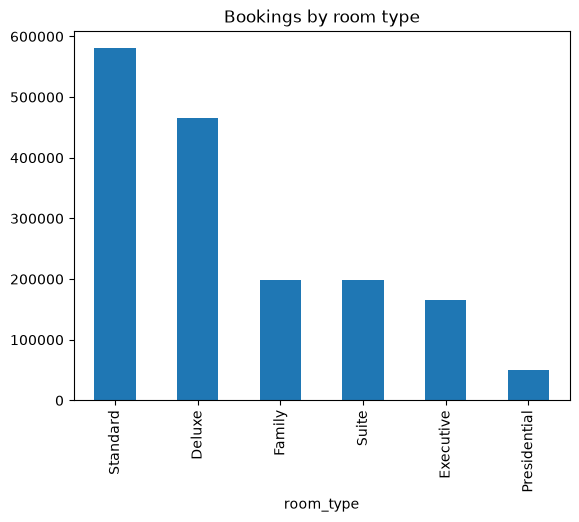

In [24]:
report["room_type"].value_counts().plot.bar(title="Bookings by room type")
plt.show()

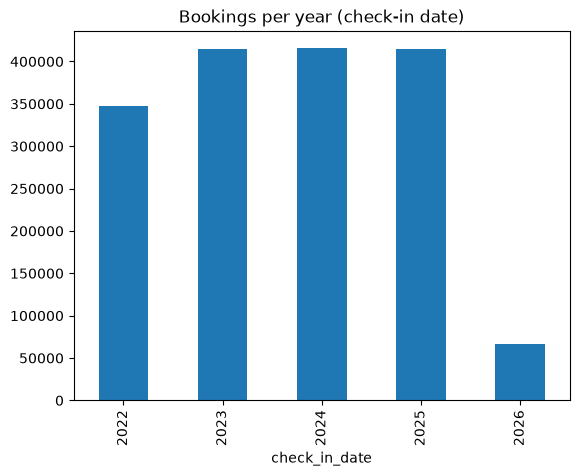

In [25]:
report["check_in_date"].dt.year.value_counts().sort_index().plot.bar(title="Bookings per year (check-in date)")
plt.show()

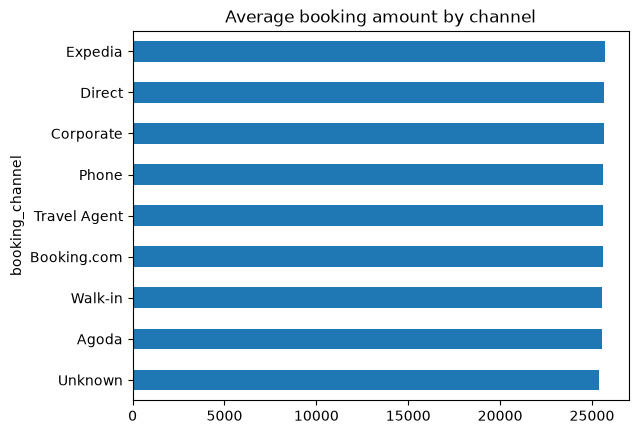

In [26]:
report.groupby("booking_channel")["total_amount"].mean().sort_values().plot.barh(title="Average booking amount by channel")
plt.show()

## Step 14: Save the clean data
The data is split into files of 500,000 rows so each file opens easily in Excel.

In [27]:
import os
import math

# Final safety check: the saved sheet must not contain phone or email
assert not {"phone", "email"} & set(report.columns), "Private columns still present!"

chunk_size = 500_000
n_rows = len(report)
n_files = math.ceil(n_rows / chunk_size)

out_dir = "report_chunks"
os.makedirs(out_dir, exist_ok=True)

for i in range(n_files):
    start = i * chunk_size
    end = start + chunk_size
    chunk = report.iloc[start:end]

    filename = os.path.join(out_dir, f"report_part_{i+1:03d}.csv")
    chunk.to_csv(filename, index=False, encoding="utf-8-sig", date_format="%Y-%m-%d")

    print(f"Saved {filename} - rows {start} to {min(end, n_rows) - 1} ({len(chunk)} rows)")

print(f"\nDone. {n_rows} rows split into {n_files} files in '{out_dir}/'")

Saved report_chunks\report_part_001.csv - rows 0 to 499999 (500000 rows)
Saved report_chunks\report_part_002.csv - rows 500000 to 999999 (500000 rows)
Saved report_chunks\report_part_003.csv - rows 1000000 to 1499999 (500000 rows)
Saved report_chunks\report_part_004.csv - rows 1500000 to 1658643 (158644 rows)

Done. 1658644 rows split into 4 files in 'report_chunks/'


## Step 15:  Exploratory Data Analysis (EDA)

Now that our dataset is thoroughly cleaned and structured, we can perform targeted exploratory analyses to uncover commercial insights. We will cover:
1. **Lead Time Analysis**: Understanding booking horizons.
2. **Revenue Patterns**: Identifying where your revenue is coming from (by hotel and booking channel).
3. **Cancellations Profiling**: Spotting traits associated with cancelled bookings.
4. **Customer Demographics & Preferences**: Age groups, top nationalities, and request behaviors.

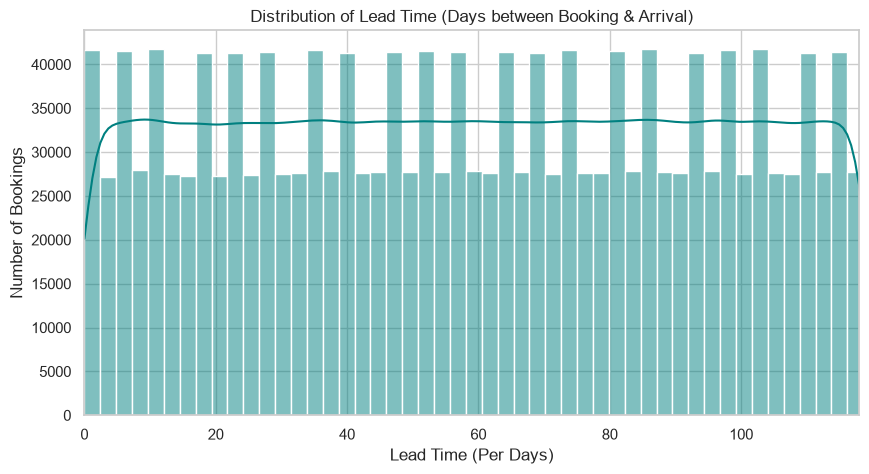

In [28]:
import seaborn as sns
sns.set_theme(style="whitegrid")

# 1. Booking Horizon / Lead Time Analysis (if booking_date & check_in_date exist)
if 'booking_date' in report.columns and 'check_in_date' in report.columns:
    report['lead_time'] = (report['check_in_date'] - report['booking_date']).dt.days

    plt.figure(figsize=(10, 5))
    sns.histplot(data=report, x='lead_time', bins=50, kde=True, color='teal')
    plt.title('Distribution of Lead Time (Days between Booking & Arrival)')
    plt.xlabel('Lead Time (Per Days)')
    plt.ylabel('Number of Bookings')
    plt.xlim(0, report['lead_time'].quantile(0.99)) # exclude outliers for better visualization
    plt.show()

In [ ]:
# 2. Revenue & Room Rate Contribution by Hotel and Room Type
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Average Room Rate per Night by Room Type
sns.barplot(ax=axes[0], data=report, x='room_type', y='room_rate_per_night', estimator=np.median, palette='Blues_r', hue='room_type', legend=False)
axes[0].set_title('Median Room Rate per Night by Room Type')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45)

# Total Revenue contribution by Hotel
report.groupby('hotel_name')['total_amount'].sum().plot.pie(
    ax=axes[1], autopct='%1.1f%%', colors=sns.color_palette('pastel'), startangle=90
)
axes[1].set_title('Total Revenue Contribution by Hotel Property')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

C:\Users\Sabbir\AppData\Local\Temp\ipykernel_36860\3406777806.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45)
C:\Users\Sabbir\AppData\Local\Temp\ipykernel_36860\3406777806.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45)


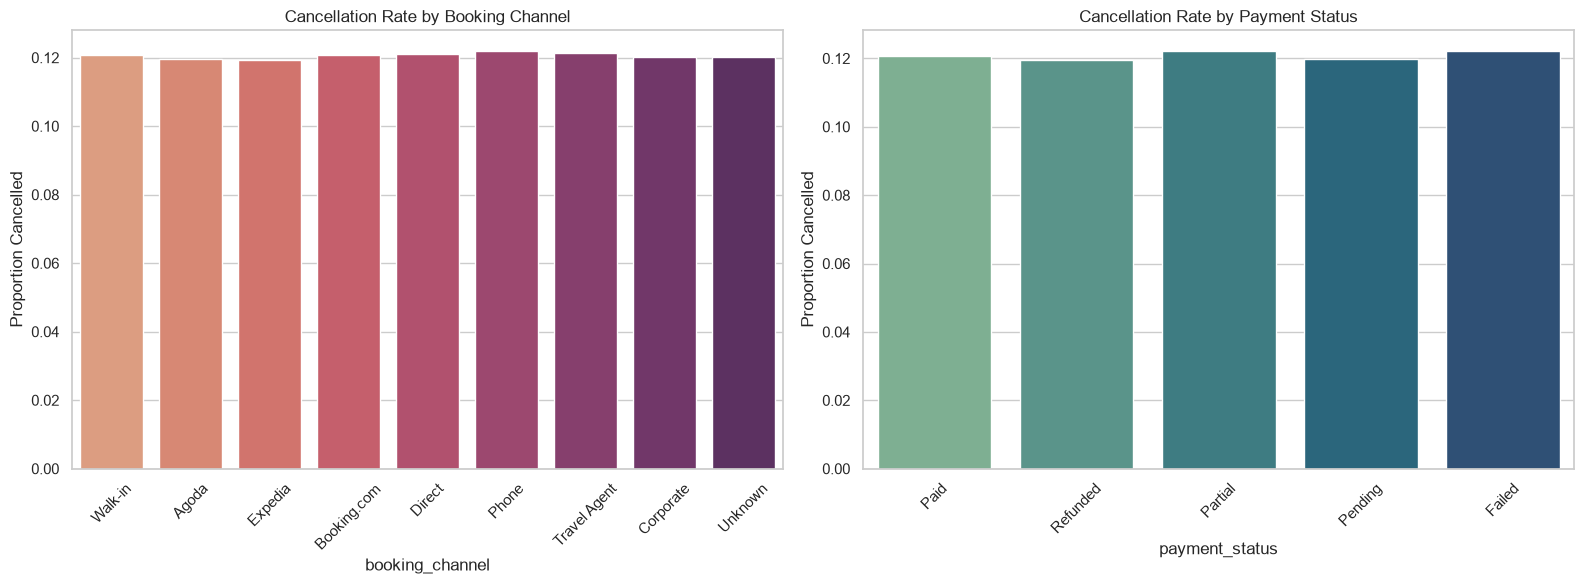

In [ ]:
# 3. Cancellation Profiling
# Understanding which payment methods or channels have the highest rate of cancellation
if 'is_cancelled' in report.columns:
    # Convert is_cancelled to numeric binary for mean calculation (percentage)
    report['cancelled_numeric'] = report['is_cancelled'].apply(lambda x: 1 if str(x).strip().title() == 'Yes' else 0)

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Cancellation Rate by Booking Channel
    sns.barplot(ax=axes[0], data=report, x='booking_channel', y='cancelled_numeric', palette='flare', errorbar=None, hue='booking_channel', legend=False)
    axes[0].set_title('Cancellation Rate by Booking Channel')
    axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45)
    axes[0].set_ylabel('Proportion Cancelled')

    # Cancellation Rate by Payment Status
    sns.barplot(ax=axes[1], data=report, x='payment_status', y='cancelled_numeric', palette='crest', errorbar=None, hue='payment_status', legend=False)
    axes[1].set_title('Cancellation Rate by Payment Status')
    axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45)
    axes[1].set_ylabel('Proportion Cancelled')

    plt.tight_layout()
    plt.show()

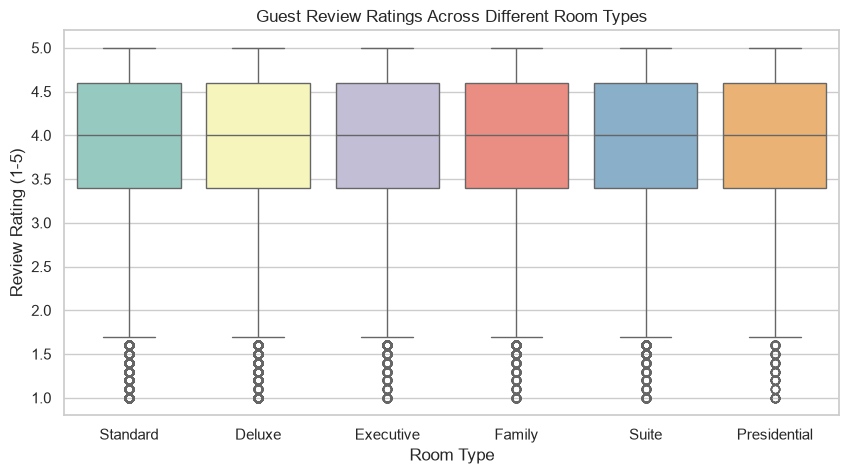

In [ ]:
# 4. Guest Demographics & Review Ratings Correlation
plt.figure(figsize=(10, 5))
sns.boxplot(data=report.dropna(subset=['review_rating']), x='room_type', y='review_rating', palette='Set3', hue='room_type', legend=False)
plt.title('Guest Review Ratings Across Different Room Types')
plt.xlabel('Room Type')
plt.ylabel('Review Rating (1-5)')
plt.show()

In [ ]:
# Group and analyze the review ratings for each room type
grouped_ratings = report.groupby('room_type')['review_rating'].describe()
display(grouped_ratings)

,count,mean,std,min,25%,50%,75%,max
room_type,,,,,,,,
Deluxe,302252.0,3.939284,0.798377,1.0,3.4,4.0,4.6,5.0
Executive,107857.0,3.939504,0.800764,1.0,3.4,4.0,4.6,5.0
Family,129721.0,3.942592,0.798208,1.0,3.4,4.0,4.6,5.0
Presidential,32432.0,3.933026,0.799619,1.0,3.4,4.0,4.6,5.0
Standard,376682.0,3.939153,0.799025,1.0,3.4,4.0,4.6,5.0
Suite,128646.0,3.939110,0.797948,1.0,3.4,4.0,4.6,5.0


## Step 16: Predictive Modeling for High-Risk Cancellations

To predict whether a booking is highly likely to be cancelled, we will:
1. Prepare our target variable (`is_cancelled` converted to binary 0 and 1).
2. Engineer features such as `lead_time`, `nights`, `room_rate_per_night`, `discount_pct`, and categorical features (`hotel_name`, `room_type`, `booking_channel`, `payment_method`).
3. One-hot encode our categorical variables.
4. Split our dataset into training and testing sets.
5. Train a Random Forest classifier to learn cancellation patterns.
6. Evaluate the model with a Classification Report and Feature Importance analysis.

In [ ]:
%pip install scikit-learn
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# Create a clean copy for modeling
model_df = report.copy()

# Define the target variable (1 for Yes, 0 for No)
model_df['target'] = model_df['is_cancelled'].apply(lambda x: 1 if str(x).strip().title() == 'Yes' else 0)

# Calculate lead_time if not already computed
if 'lead_time' not in model_df.columns:
    model_df['lead_time'] = (model_df['check_in_date'] - model_df['booking_date']).dt.days

# Handle any missing values in essential numerical features
model_df['lead_time'] = model_df['lead_time'].fillna(model_df['lead_time'].median())
model_df['nights'] = model_df['nights'].fillna(model_df['nights'].median())
model_df['room_rate_per_night'] = model_df['room_rate_per_night'].fillna(model_df['room_rate_per_night'].median())

# Select predictor features
numerical_features = ['lead_time', 'nights', 'room_rate_per_night', 'discount_pct', 'age', 'num_guests']
categorical_features = ['hotel_name', 'room_type', 'booking_channel', 'payment_method']

# Get dummies for categorical variables
X_categorical = pd.get_dummies(model_df[categorical_features], drop_first=True)
X_numerical = model_df[numerical_features]

X = pd.concat([X_numerical, X_categorical], axis=1)
y = model_df['target']

# Split the dataset into 80% train and 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set size: {X_train.shape}")
print(f"Testing set size: {X_test.shape}")

Note: you may need to restart the kernel to use updated packages.
Training set size: (1326915, 31)
Testing set size: (331729, 31)


In [ ]:
# Train the Random Forest Model with class balancing to handle the target imbalance
rf_model = RandomForestClassifier(n_estimators=100, max_depth=12, class_weight='balanced', random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

# Make predictions
y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

# Print metrics
print("Classification Report (After Class Balancing):")
print(classification_report(y_test, y_pred))
print(f"ROC AUC Score: {roc_auc_score(y_test, y_prob):.4f}")

Classification Report (After Class Balancing):
              precision    recall  f1-score   support

           0       0.88      0.60      0.71    291719
           1       0.12      0.40      0.19     40010

    accuracy                           0.57    331729
   macro avg       0.50      0.50      0.45    331729
weighted avg       0.79      0.57      0.65    331729

ROC AUC Score: 0.4985


C:\Users\Sabbir\AppData\Local\Temp\ipykernel_36860\3377267894.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances[indices][:10], y=X.columns[indices][:10], palette="viridis")


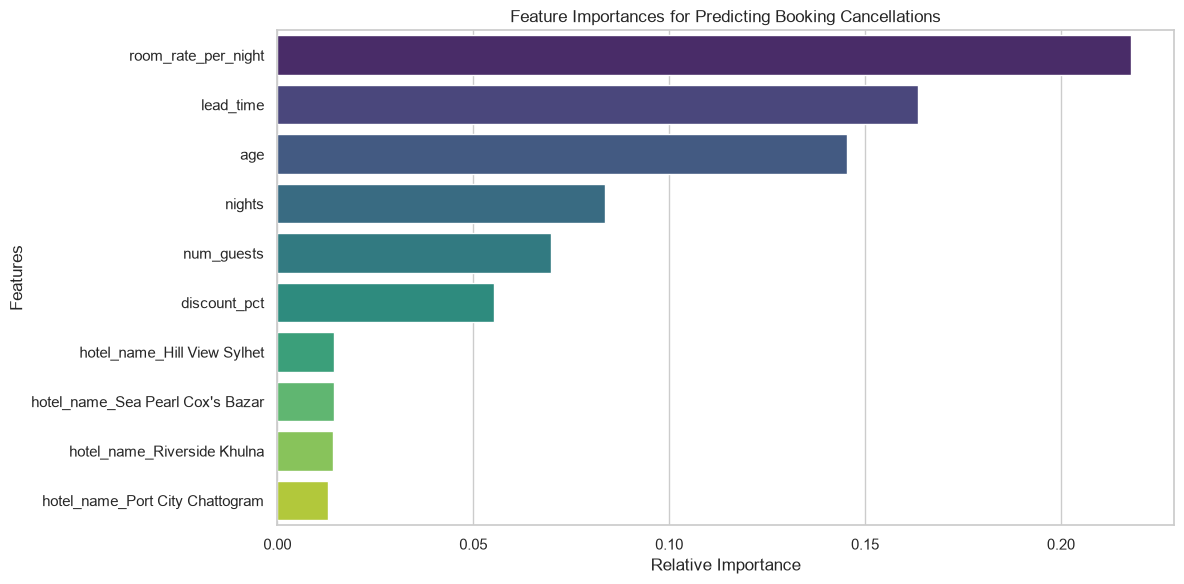

In [ ]:
# Plot Feature Importances
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(12, 6))
plt.title("Feature Importances for Predicting Booking Cancellations")
sns.barplot(x=importances[indices][:10], y=X.columns[indices][:10], palette="viridis")
plt.xlabel("Relative Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

### Confusion Matrix Visualization

To see exactly how many true non-cancellations (0) and cancellations (1) are being correctly identified versus misclassified, we will plot a normalized and non-normalized confusion matrix.

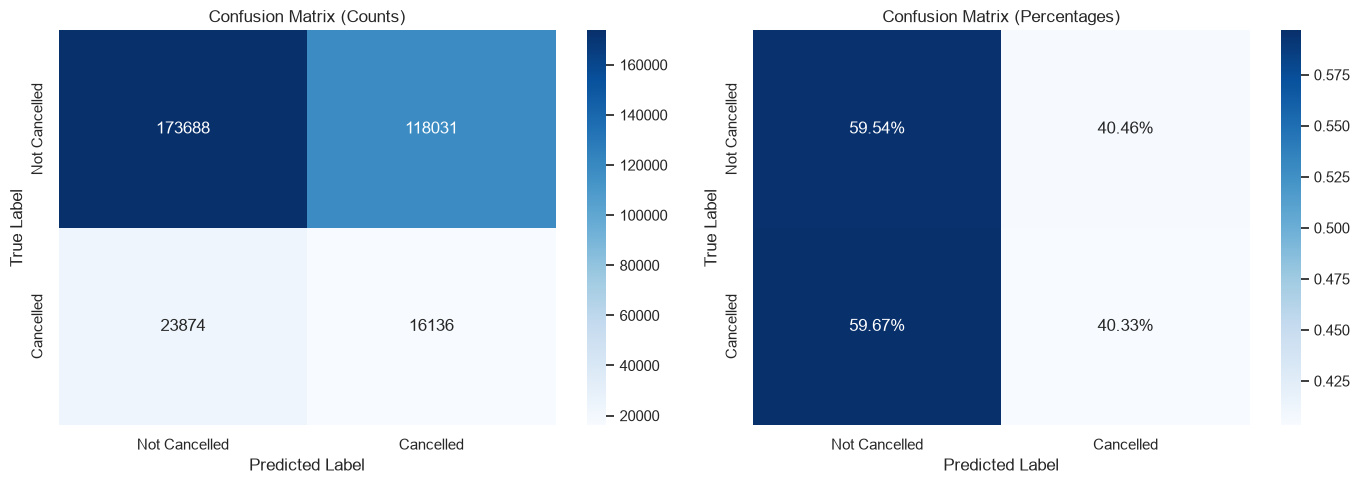

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Compute normalized confusion matrix for percentage views
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot raw counts confusion matrix
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Not Cancelled", "Cancelled"],
            yticklabels=["Not Cancelled", "Cancelled"])
axes[0].set_title("Confusion Matrix (Counts)")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

# Plot normalized confusion matrix
sns.heatmap(cm_normalized, annot=True, fmt=".2%", cmap="Blues", ax=axes[1],
            xticklabels=["Not Cancelled", "Cancelled"],
            yticklabels=["Not Cancelled", "Cancelled"])
axes[1].set_title("Confusion Matrix (Percentages)")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

plt.tight_layout()
plt.show()